In [1]:
import os
import tarfile
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
# Main directories

BASE_DIR = Path("/kaggle/working")

# Raw extracted E-DAIC files that we want to keep
EXTRACTED_DIR = BASE_DIR / "edaic_extracted"

# Temporary files
TEMP_DIR = BASE_DIR / "edaic_tmp"

# Final participant-level feature dataset
FEATURE_DIR = BASE_DIR / "edaic_features"

EXTRACTED_DIR.mkdir(exist_ok=True)
TEMP_DIR.mkdir(exist_ok=True)
FEATURE_DIR.mkdir(exist_ok=True)

print("Extracted data :", EXTRACTED_DIR)
print("Temporary data :", TEMP_DIR)
print("Feature data   :", FEATURE_DIR)

Extracted data : /kaggle/working/edaic_extracted
Temporary data : /kaggle/working/edaic_tmp
Feature data   : /kaggle/working/edaic_features


In [3]:
# BLOCK 3 — Download E-DAIC label files using wget

import os
from pathlib import Path

BASE_URL = "https://dcapswoz.ict.usc.edu/wwwedaic"

LABELS_DIR = Path("/kaggle/working/labels")
LABELS_DIR.mkdir(exist_ok=True)

label_urls = {
    "train_split.csv":
        f"{BASE_URL}/labels/train_split.csv",

    "dev_split.csv":
        f"{BASE_URL}/labels/dev_split.csv",

    "test_split.csv":
        f"{BASE_URL}/labels/test_split.csv",

    "Detailed_PHQ8_Labels.csv":
        f"{BASE_URL}/labels/Detailed_PHQ8_Labels.csv",

    "detailed_lables.csv":
        f"{BASE_URL}/labels/detailed_lables.csv"
}

for filename, url in label_urls.items():

    output_path = LABELS_DIR / filename

    if output_path.exists():
        print(f"{filename} already exists. Skipping.")
        continue

    print(f"Downloading {filename}...")

    result = os.system(
        f"wget -q "
        f"-O '{output_path}' "
        f"'{url}'"
    )

    if result != 0:
        print(f"FAILED: {filename}")
    else:
        print(f"Downloaded: {filename}")

print("\nLabel download complete.")

Downloaded: train_split.csv
Downloaded: dev_split.csv
Downloaded: test_split.csv
Downloaded: Detailed_PHQ8_Labels.csv
Downloaded: detailed_lables.csv

Label download complete.


In [4]:
# BLOCK 4 — Load labels

train = pd.read_csv(
    LABELS_DIR / "train_split.csv"
)

dev = pd.read_csv(
    LABELS_DIR / "dev_split.csv"
)

test = pd.read_csv(
    LABELS_DIR / "test_split.csv"
)

phq_details = pd.read_csv(
    LABELS_DIR / "Detailed_PHQ8_Labels.csv"
)

detailed_labels = pd.read_csv(
    LABELS_DIR / "detailed_lables.csv"
)

print("Train:", train.shape)
print("Dev:", dev.shape)
print("Test:", test.shape)
print("PHQ details:", phq_details.shape)
print("Detailed labels:", detailed_labels.shape)

Train: (163, 6)
Dev: (56, 6)
Test: (56, 6)
PHQ details: (219, 10)
Detailed labels: (275, 33)


In [5]:
train["Split"] = "train"
dev["Split"] = "dev"
test["Split"] = "test"

labels = pd.concat(
    [train, dev, test],
    ignore_index=True
)

print("Total participants:", len(labels))
print(
    "Unique participants:",
    labels["Participant_ID"].nunique()
)

display(labels.head())

Total participants: 275
Unique participants: 275


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
0,302,male,0,4,0,28.0,train
1,303,female,0,0,0,17.0,train
2,304,female,0,6,0,20.0,train
3,305,male,0,7,0,28.0,train
4,307,female,0,4,0,23.0,train


In [6]:
print("Duplicate participant IDs:")
print(labels["Participant_ID"].duplicated().sum())

print("\nTrain ∩ Dev:")
print(
    set(train["Participant_ID"])
    &
    set(dev["Participant_ID"])
)

print("\nTrain ∩ Test:")
print(
    set(train["Participant_ID"])
    &
    set(test["Participant_ID"])
)

print("\nDev ∩ Test:")
print(
    set(dev["Participant_ID"])
    &
    set(test["Participant_ID"])
)

Duplicate participant IDs:
0

Train ∩ Dev:
set()

Train ∩ Test:
set()

Dev ∩ Test:
set()


In [7]:
print("PHQ Binary distribution:")
display(
    labels["PHQ_Binary"]
    .value_counts()
    .sort_index()
)

print("\nPHQ Score:")
display(
    labels["PHQ_Score"]
    .describe()
)

print("\nPTSD Severity:")
display(
    labels["PTSD Severity"]
    .describe()
)

print("\nGender:")
display(
    labels["Gender"]
    .value_counts()
)

PHQ Binary distribution:


PHQ_Binary
0    209
1     66
Name: count, dtype: int64


PHQ Score:


count    275.000000
mean       6.941818
std        6.108230
min        0.000000
25%        2.000000
50%        6.000000
75%       11.000000
max       23.000000
Name: PHQ_Score, dtype: float64


PTSD Severity:


count    273.000000
mean      36.443223
std       17.391404
min       17.000000
25%       22.000000
50%       30.000000
75%       50.000000
max       85.000000
Name: PTSD Severity, dtype: float64


Gender:


Gender
male       168
female     103
female       2
male         2
Name: count, dtype: int64

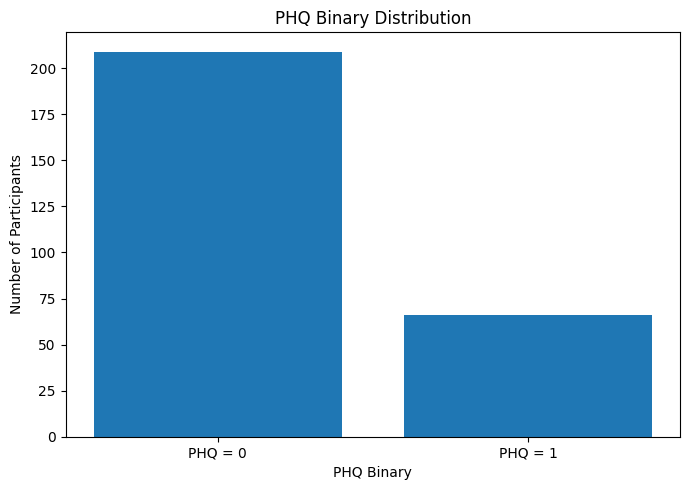

In [8]:
counts = (
    labels["PHQ_Binary"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(7, 5))

plt.bar(
    ["PHQ = 0", "PHQ = 1"],
    counts.values
)

plt.xlabel("PHQ Binary")
plt.ylabel("Number of Participants")
plt.title("PHQ Binary Distribution")

plt.tight_layout()
plt.show()

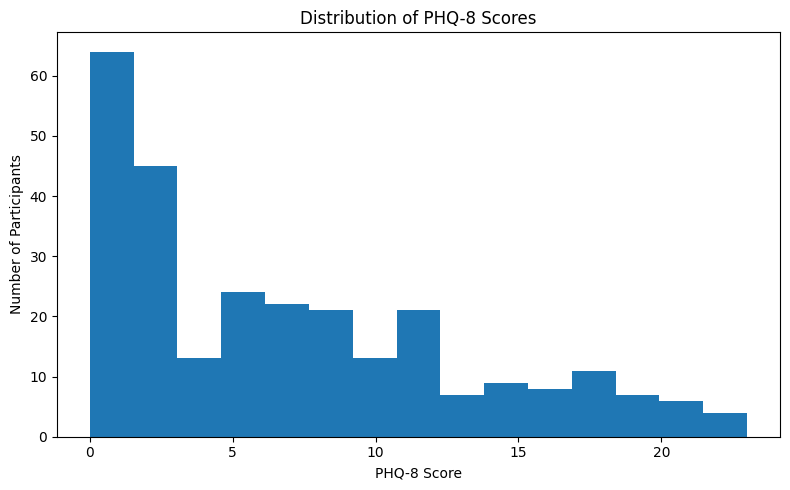

In [9]:
plt.figure(figsize=(8, 5))

plt.hist(
    labels["PHQ_Score"],
    bins=15
)

plt.xlabel("PHQ-8 Score")
plt.ylabel("Number of Participants")
plt.title("Distribution of PHQ-8 Scores")

plt.tight_layout()
plt.show()

/tmp/ipykernel_16/64720079.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


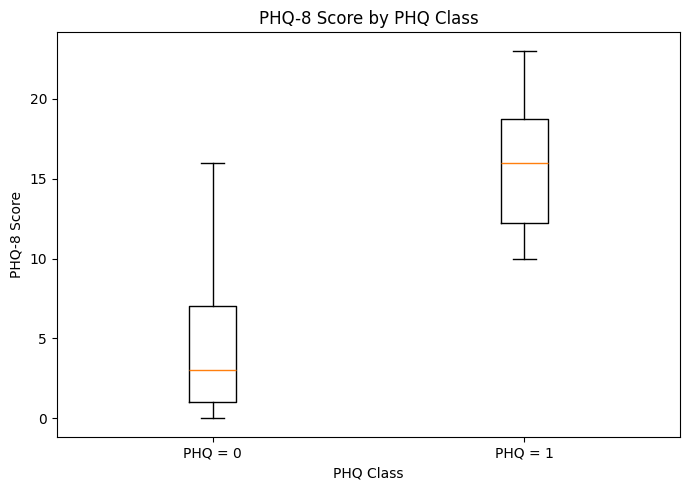

In [10]:
phq0 = labels.loc[
    labels["PHQ_Binary"] == 0,
    "PHQ_Score"
].dropna()

phq1 = labels.loc[
    labels["PHQ_Binary"] == 1,
    "PHQ_Score"
].dropna()

plt.figure(figsize=(7, 5))

plt.boxplot(
    [phq0, phq1],
    labels=["PHQ = 0", "PHQ = 1"]
)

plt.xlabel("PHQ Class")
plt.ylabel("PHQ-8 Score")
plt.title("PHQ-8 Score by PHQ Class")

plt.tight_layout()
plt.show()

In [11]:
DATA_BASE_URL = (
    "https://dcapswoz.ict.usc.edu/wwwedaic/data"
)

print(DATA_BASE_URL)

https://dcapswoz.ict.usc.edu/wwwedaic/data


In [12]:
# BLOCK 12 — Download participant archive silently
# Save only eGeMAPS, MFCC and Transcript

import os
import tarfile
from pathlib import Path

DATA_BASE_URL = (
    "https://dcapswoz.ict.usc.edu/wwwedaic/data"
)

EXTRACTED_DIR = Path(
    "/kaggle/working/edaic_extracted"
)

TEMP_DIR = Path(
    "/kaggle/working/edaic_tmp"
)

EXTRACTED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TEMP_DIR.mkdir(
    parents=True,
    exist_ok=True
)


def download_and_extract_participant(pid):

    pid = int(pid)

    participant_dir = (
        EXTRACTED_DIR / f"{pid}_P"
    )

    features_dir = (
        participant_dir / "features"
    )

    participant_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    features_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # Files we want to keep
    required_files = {

        f"{pid}_Transcript.csv":
            participant_dir / f"{pid}_Transcript.csv",

        f"{pid}_OpenSMILE2.3.0_egemaps.csv":
            features_dir /
            f"{pid}_OpenSMILE2.3.0_egemaps.csv",

        f"{pid}_OpenSMILE2.3.0_mfcc.csv":
            features_dir /
            f"{pid}_OpenSMILE2.3.0_mfcc.csv"
    }

    # If all required files already exist,
    # don't download again.
    if all(
        path.exists()
        for path in required_files.values()
    ):

        print(
            f"{pid}: files already exist."
        )

        return (
            required_files[
                f"{pid}_OpenSMILE2.3.0_egemaps.csv"
            ],
            required_files[
                f"{pid}_OpenSMILE2.3.0_mfcc.csv"
            ]
        )

    archive = (
        TEMP_DIR / f"{pid}_P.tar.gz"
    )

    url = (
        f"{DATA_BASE_URL}/{pid}_P.tar.gz"
    )

    print(
        f"{pid}: downloading..."
    )

    # IMPORTANT:
    # -q = completely quiet
    # No --show-progress
    result = os.system(
        f"wget -q "
        f"-O '{archive}' "
        f"'{url}'"
    )

    if result != 0 or not archive.exists():

        raise RuntimeError(
            f"Download failed for participant {pid}"
        )

    print(
        f"{pid}: extracting required files..."
    )

    try:

        with tarfile.open(
            archive,
            "r:gz"
        ) as tar:

            members = tar.getmembers()

            found = set()

            for member in members:

                basename = os.path.basename(
                    member.name
                )

                if basename not in required_files:
                    continue

                output_path = (
                    required_files[basename]
                )

                file_obj = tar.extractfile(
                    member
                )

                if file_obj is None:
                    continue

                with open(
                    output_path,
                    "wb"
                ) as output:

                    while True:

                        chunk = file_obj.read(
                            1024 * 1024
                        )

                        if not chunk:
                            break

                        output.write(chunk)

                found.add(basename)

        missing = (
            set(required_files.keys())
            - found
        )

        if missing:

            raise FileNotFoundError(
                f"{pid}: missing files: {missing}"
            )

        print(
            f"{pid}: extraction complete."
        )

        return (
            required_files[
                f"{pid}_OpenSMILE2.3.0_egemaps.csv"
            ],
            required_files[
                f"{pid}_OpenSMILE2.3.0_mfcc.csv"
            ]
        )

    finally:

        # Delete large temporary archive
        if archive.exists():
            archive.unlink()

        print(
            f"{pid}: temporary archive deleted."
        )

In [13]:
def aggregate_features(df, prefix):

    feature_cols = [
        c for c in df.columns
        if c not in ["name", "frameTime"]
    ]

    x = df[feature_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    # OpenSMILE invalid/sentinel value
    x = x.replace(-201, np.nan)

    # Infinite values
    x = x.replace(
        [np.inf, -np.inf],
        np.nan
    )

    result = {}

    for col in feature_cols:

        result[
            f"{prefix}_{col}_mean"
        ] = x[col].mean()

        result[
            f"{prefix}_{col}_std"
        ] = x[col].std()

        result[
            f"{prefix}_{col}_median"
        ] = x[col].median()

    return pd.Series(result)

In [14]:
test_pid = 302

eg_path, mfcc_path = (
    download_and_extract_participant(
        test_pid
    )
)

print("\neGeMAPS:")
print(eg_path)

print("\nMFCC:")
print(mfcc_path)

302: downloading...
302: extracting required files...
302: extraction complete.
302: temporary archive deleted.

eGeMAPS:
/kaggle/working/edaic_extracted/302_P/features/302_OpenSMILE2.3.0_egemaps.csv

MFCC:
/kaggle/working/edaic_extracted/302_P/features/302_OpenSMILE2.3.0_mfcc.csv


In [15]:
participant_302 = (
    EXTRACTED_DIR / "302_P"
)

print("Files saved:")
!find /kaggle/working/edaic_extracted/302_P -type f | sort

Files saved:
/kaggle/working/edaic_extracted/302_P/302_Transcript.csv
/kaggle/working/edaic_extracted/302_P/features/302_OpenSMILE2.3.0_egemaps.csv
/kaggle/working/edaic_extracted/302_P/features/302_OpenSMILE2.3.0_mfcc.csv


In [16]:
eg = pd.read_csv(
    eg_path,
    sep=";"
)

mfcc = pd.read_csv(
    mfcc_path,
    sep=";"
)

print(
    "eGeMAPS shape:",
    eg.shape
)

print(
    "MFCC shape:",
    mfcc.shape
)

display(eg.head())
display(mfcc.head())

eGeMAPS shape: (75876, 25)
MFCC shape: (75878, 41)


,name,frameTime,Loudness_sma3,alphaRatio_sma3,hammarbergIndex_sma3,slope0-500_sma3,slope500-1500_sma3,spectralFlux_sma3,mfcc1_sma3,mfcc2_sma3,...,HNRdBACF_sma3nz,logRelF0-H1-H2_sma3nz,logRelF0-H1-A3_sma3nz,F1frequency_sma3nz,F1bandwidth_sma3nz,F1amplitudeLogRelF0_sma3nz,F2frequency_sma3nz,F2amplitudeLogRelF0_sma3nz,F3frequency_sma3nz,F3amplitudeLogRelF0_sma3nz
0,'unknown',0.00,0.050650,-16.581980,29.12192,-0.016335,0.010312,0.003262,10.706830,12.200000,...,0.0,0.0,0.0,803.8763,1516.107,-201.0,1780.781,-201.0,2704.956,-201.0
1,'unknown',0.01,0.053357,-14.861850,27.29627,-0.019814,0.010204,0.005267,10.051070,10.803070,...,0.0,0.0,0.0,639.0214,1568.043,-201.0,1559.670,-201.0,2456.526,-201.0
2,'unknown',0.02,0.055600,-11.754340,24.25732,-0.011439,0.012616,0.008341,9.210052,8.632755,...,0.0,0.0,0.0,509.3781,1608.235,-201.0,1315.770,-201.0,2125.850,-201.0
3,'unknown',0.03,0.057076,-9.450172,19.58037,-0.010206,0.012342,0.007102,8.742709,6.598707,...,0.0,0.0,0.0,502.1831,1510.600,-201.0,1434.698,-201.0,2235.370,-201.0
4,'unknown',0.04,0.055917,-8.611698,18.04498,-0.010222,0.014551,0.007270,9.253143,7.205553,...,0.0,0.0,0.0,490.9701,1428.711,-201.0,1407.846,-201.0,2270.155,-201.0


,name,frameTime,pcm_fftMag_mfcc[0],pcm_fftMag_mfcc[1],pcm_fftMag_mfcc[2],pcm_fftMag_mfcc[3],pcm_fftMag_mfcc[4],pcm_fftMag_mfcc[5],pcm_fftMag_mfcc[6],pcm_fftMag_mfcc[7],...,pcm_fftMag_mfcc_de_de[3],pcm_fftMag_mfcc_de_de[4],pcm_fftMag_mfcc_de_de[5],pcm_fftMag_mfcc_de_de[6],pcm_fftMag_mfcc_de_de[7],pcm_fftMag_mfcc_de_de[8],pcm_fftMag_mfcc_de_de[9],pcm_fftMag_mfcc_de_de[10],pcm_fftMag_mfcc_de_de[11],pcm_fftMag_mfcc_de_de[12]
0,'unknown',0.00,-16.49069,3.284656,-0.047574,-7.088384,1.317602,-2.347494,8.179334,-12.602680,...,-0.123991,-0.151829,0.013615,-0.083641,0.354018,0.689320,-0.633814,-0.276949,-0.041297,-0.024466
1,'unknown',0.01,-15.73779,1.403919,-0.359134,-13.747690,-3.611933,-7.186287,4.942978,-15.489380,...,0.205593,0.459108,0.328591,-0.032162,0.518136,1.079323,-1.309899,-0.702328,-0.968478,-0.113452
2,'unknown',0.02,-17.67352,-2.092532,1.913712,0.046178,0.231022,-5.102201,8.752654,-6.547929,...,-0.137977,0.972017,0.392305,-0.123437,0.236716,0.842740,-1.206577,-0.932375,-1.364911,-0.212339
3,'unknown',0.03,-18.77698,-5.650746,-8.582227,-7.530021,-1.499785,-3.083436,1.683900,-6.827036,...,-0.327217,1.100109,0.247522,-0.158897,0.029950,0.333332,-0.047620,-0.037720,-1.482966,-0.274606
4,'unknown',0.04,-16.52310,-1.317858,-4.141658,-9.152447,-7.180878,-10.763040,9.254951,-5.567800,...,-0.271022,0.439733,0.206436,-0.474150,-0.274279,0.161990,2.255325,1.522572,-0.367573,-0.143348


In [17]:
transcript_path = (
    EXTRACTED_DIR
    / "302_P"
    / "302_Transcript.csv"
)

transcript = pd.read_csv(
    transcript_path
)

print(
    "Transcript shape:",
    transcript.shape
)

print(
    "Transcript columns:"
)

print(
    transcript.columns.tolist()
)

display(
    transcript.head(10)
)

Transcript shape: (99, 4)
Transcript columns:
['Start_Time', 'End_Time', 'Text', 'Confidence']


,Start_Time,End_Time,Text,Confidence
0,2.1,3.2,just move around a little bit,0.906568
1,26.3,27.1,when you're finished,0.793796
2,58.2,59.1,how are you doing today,0.859790
3,59.6,61.0,I'm fine how about yourself,0.987629
4,66.6,67.3,where you from,0.911304
5,69.0,71.2,from Los Angeles California,0.981870
6,75.0,75.8,what park,0.760542
7,79.8,80.3,okay,0.976541
8,84.3,88.5,on my family's here friends,0.798182
9,89.4,92.1,make sure people and a lot of things to do,0.864039


In [18]:
eg_acoustic = eg.drop(
    columns=["name", "frameTime"]
)

invalid_counts = (
    (eg_acoustic == -201)
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    invalid_counts.head(15)
)

total_values = eg_acoustic.size

total_invalid = (
    eg_acoustic == -201
).sum().sum()

invalid_percentage = (
    total_invalid /
    total_values *
    100
)

print(
    f"Total eGeMAPS values: "
    f"{total_values:,}"
)

print(
    f"Total -201 values: "
    f"{total_invalid:,}"
)

print(
    f"Overall -201 percentage: "
    f"{invalid_percentage:.2f}%"
)

F1amplitudeLogRelF0_sma3nz     59891
F2amplitudeLogRelF0_sma3nz     59725
F3amplitudeLogRelF0_sma3nz     59725
slope0-500_sma3                    0
Loudness_sma3                      0
alphaRatio_sma3                    0
hammarbergIndex_sma3               0
mfcc1_sma3                         0
spectralFlux_sma3                  0
slope500-1500_sma3                 0
mfcc2_sma3                         0
jitterLocal_sma3nz                 0
mfcc3_sma3                         0
mfcc4_sma3                         0
F0semitoneFrom27.5Hz_sma3nz        0
dtype: int64

Total eGeMAPS values: 1,745,148
Total -201 values: 179,341
Overall -201 percentage: 10.28%


In [19]:
eg_agg = aggregate_features(
    eg,
    "eg"
)

mfcc_agg = aggregate_features(
    mfcc,
    "mfcc"
)

print(
    "eGeMAPS aggregated features:",
    len(eg_agg)
)

print(
    "MFCC aggregated features:",
    len(mfcc_agg)
)

eGeMAPS aggregated features: 69
MFCC aggregated features: 117


In [20]:
row = pd.concat(
    [eg_agg, mfcc_agg]
)

row["Feature_Duration_sec"] = (
    eg["frameTime"].max()
)

row["eGeMAPS_Frames"] = len(eg)
row["MFCC_Frames"] = len(mfcc)

row["Participant_ID"] = test_pid

row = row.to_frame().T

display(row.head())
print("Shape:", row.shape)

,eg_Loudness_sma3_mean,eg_Loudness_sma3_std,eg_Loudness_sma3_median,eg_alphaRatio_sma3_mean,eg_alphaRatio_sma3_std,eg_alphaRatio_sma3_median,eg_hammarbergIndex_sma3_mean,eg_hammarbergIndex_sma3_std,eg_hammarbergIndex_sma3_median,eg_slope0-500_sma3_mean,...,mfcc_pcm_fftMag_mfcc_de_de[11]_mean,mfcc_pcm_fftMag_mfcc_de_de[11]_std,mfcc_pcm_fftMag_mfcc_de_de[11]_median,mfcc_pcm_fftMag_mfcc_de_de[12]_mean,mfcc_pcm_fftMag_mfcc_de_de[12]_std,mfcc_pcm_fftMag_mfcc_de_de[12]_median,Feature_Duration_sec,eGeMAPS_Frames,MFCC_Frames,Participant_ID
0,0.094199,0.060997,0.065453,-15.264085,4.494209,-15.325215,25.444097,5.621548,25.7998,-0.021518,...,-0.000037,1.017816,-0.001629,-0.000009,0.40343,0.000887,758.75,75876.0,75878.0,302.0


Shape: (1, 190)


In [21]:
row = row.merge(
    labels[
        [
            "Participant_ID",
            "Gender",
            "PHQ_Binary",
            "PHQ_Score",
            "PCL-C (PTSD)",
            "PTSD Severity",
            "Split"
        ]
    ],
    on="Participant_ID",
    how="left"
)

display(row.head())

,eg_Loudness_sma3_mean,eg_Loudness_sma3_std,eg_Loudness_sma3_median,eg_alphaRatio_sma3_mean,eg_alphaRatio_sma3_std,eg_alphaRatio_sma3_median,eg_hammarbergIndex_sma3_mean,eg_hammarbergIndex_sma3_std,eg_hammarbergIndex_sma3_median,eg_slope0-500_sma3_mean,...,Feature_Duration_sec,eGeMAPS_Frames,MFCC_Frames,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
0,0.094199,0.060997,0.065453,-15.264085,4.494209,-15.325215,25.444097,5.621548,25.7998,-0.021518,...,758.75,75876.0,75878.0,302.0,male,0,4,0,28.0,train


In [22]:
print(
    "Participant:",
    row["Participant_ID"].iloc[0]
)

print(
    "PHQ Binary:",
    row["PHQ_Binary"].iloc[0]
)

print(
    "PHQ Score:",
    row["PHQ_Score"].iloc[0]
)

print(
    "Split:",
    row["Split"].iloc[0]
)

Participant: 302.0
PHQ Binary: 0
PHQ Score: 4
Split: train


In [23]:
FINAL_FEATURE_FILE = (
    FEATURE_DIR /
    "edaic_audio_features.csv"
)

print(
    "Final feature file:",
    FINAL_FEATURE_FILE
)

Final feature file: /kaggle/working/edaic_features/edaic_audio_features.csv


In [24]:
if FINAL_FEATURE_FILE.exists():

    existing_features = pd.read_csv(
        FINAL_FEATURE_FILE
    )

    processed_ids = set(
        existing_features[
            "Participant_ID"
        ].astype(int)
    )

    print(
        f"Already processed: "
        f"{len(processed_ids)} participants"
    )

else:

    existing_features = pd.DataFrame()

    processed_ids = set()

    print(
        "No existing feature dataset."
    )

No existing feature dataset.


In [25]:
# BLOCK 25 — Process all training participants

train_ids = (
    train["Participant_ID"]
    .astype(int)
    .tolist()
)

failed_ids = []

for i, pid in enumerate(train_ids):

    if pid in processed_ids:

        print(
            f"[{i+1}/{len(train_ids)}] "
            f"{pid} already processed"
        )

        continue

    try:

        print(
            f"\n[{i+1}/{len(train_ids)}] "
            f"Processing participant {pid}"
        )

        # Download + save eGeMAPS, MFCC, Transcript
        eg_path, mfcc_path = (
            download_and_extract_participant(
                pid
            )
        )

        # Load acoustic features
        eg = pd.read_csv(
            eg_path,
            sep=";"
        )

        mfcc = pd.read_csv(
            mfcc_path,
            sep=";"
        )

        # Aggregate
        eg_agg = aggregate_features(
            eg,
            "eg"
        )

        mfcc_agg = aggregate_features(
            mfcc,
            "mfcc"
        )

        # Combine
        row = pd.concat(
            [
                eg_agg,
                mfcc_agg
            ]
        )

        # Temporal information
        row["Feature_Duration_sec"] = (
            eg["frameTime"].max()
        )

        row["eGeMAPS_Frames"] = len(eg)
        row["MFCC_Frames"] = len(mfcc)

        row["Participant_ID"] = pid

        row = row.to_frame().T

        # Add labels
        row = row.merge(
            labels[
                [
                    "Participant_ID",
                    "Gender",
                    "PHQ_Binary",
                    "PHQ_Score",
                    "PCL-C (PTSD)",
                    "PTSD Severity",
                    "Split"
                ]
            ],
            on="Participant_ID",
            how="left"
        )

        # Save immediately
        row.to_csv(
            FINAL_FEATURE_FILE,
            mode="a",
            header=(
                not FINAL_FEATURE_FILE.exists()
            ),
            index=False
        )

        processed_ids.add(pid)

        print(
            f"✓ {pid} completed"
        )

    except Exception as e:

        print(
            f"✗ {pid} FAILED: {e}"
        )

        failed_ids.append(pid)


print("\n==============================")
print("PROCESSING COMPLETE")
print("==============================")

print(
    "Successful:",
    len(processed_ids)
)

print(
    "Failed:",
    len(failed_ids)
)

if failed_ids:
    print(
        "Failed IDs:",
        failed_ids
    )


[1/163] Processing participant 302
302: files already exist.
✓ 302 completed

[2/163] Processing participant 303
303: downloading...
303: extracting required files...
303: extraction complete.
303: temporary archive deleted.
✓ 303 completed

[3/163] Processing participant 304
304: downloading...
304: extracting required files...
304: extraction complete.
304: temporary archive deleted.
✓ 304 completed

[4/163] Processing participant 305
305: downloading...
305: extracting required files...
305: extraction complete.
305: temporary archive deleted.
✓ 305 completed

[5/163] Processing participant 307
307: downloading...
307: extracting required files...
307: extraction complete.
307: temporary archive deleted.
✓ 307 completed

[6/163] Processing participant 308
308: downloading...
308: extracting required files...
308: extraction complete.
308: temporary archive deleted.
✓ 308 completed

[7/163] Processing participant 309
309: downloading...
309: extracting required files...
309: extract

In [26]:
audio_train = pd.read_csv(
    FINAL_FEATURE_FILE
)

print(
    "Audio training dataset shape:",
    audio_train.shape
)

display(
    audio_train.head()
)

Audio training dataset shape: (163, 196)


,eg_Loudness_sma3_mean,eg_Loudness_sma3_std,eg_Loudness_sma3_median,eg_alphaRatio_sma3_mean,eg_alphaRatio_sma3_std,eg_alphaRatio_sma3_median,eg_hammarbergIndex_sma3_mean,eg_hammarbergIndex_sma3_std,eg_hammarbergIndex_sma3_median,eg_slope0-500_sma3_mean,...,Feature_Duration_sec,eGeMAPS_Frames,MFCC_Frames,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
0,0.094199,0.060997,0.065453,-15.264085,4.494209,-15.325215,25.444097,5.621548,25.799800,-0.021518,...,758.75,75876.0,75878.0,302.0,male,0,4,0,28.0,train
1,0.161740,0.134863,0.098868,-14.996058,5.863149,-15.433840,25.766606,7.041171,26.213365,-0.003281,...,985.25,98526.0,98528.0,303.0,female,0,0,0,17.0,train
2,0.123654,0.110712,0.074131,-15.657376,5.480203,-16.078585,25.482295,6.753119,26.058590,-0.009425,...,792.55,79256.0,79258.0,304.0,female,0,6,0,20.0,train
3,0.484929,0.373775,0.351518,-17.771436,5.520051,-18.386525,30.458521,6.591521,31.074590,-0.004643,...,1703.95,170396.0,170398.0,305.0,male,0,7,0,28.0,train
4,0.640995,0.490607,0.485032,-16.423802,6.951102,-17.241960,26.587544,8.991652,27.781150,0.011665,...,1238.78,123872.0,123878.0,307.0,female,0,4,0,23.0,train


In [27]:
audio_train = pd.read_csv(
    "/kaggle/working/edaic_features/edaic_audio_features.csv"
)

print("Shape:", audio_train.shape)

display(audio_train.head())

Shape: (163, 196)


,eg_Loudness_sma3_mean,eg_Loudness_sma3_std,eg_Loudness_sma3_median,eg_alphaRatio_sma3_mean,eg_alphaRatio_sma3_std,eg_alphaRatio_sma3_median,eg_hammarbergIndex_sma3_mean,eg_hammarbergIndex_sma3_std,eg_hammarbergIndex_sma3_median,eg_slope0-500_sma3_mean,...,Feature_Duration_sec,eGeMAPS_Frames,MFCC_Frames,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity,Split
0,0.094199,0.060997,0.065453,-15.264085,4.494209,-15.325215,25.444097,5.621548,25.799800,-0.021518,...,758.75,75876.0,75878.0,302.0,male,0,4,0,28.0,train
1,0.161740,0.134863,0.098868,-14.996058,5.863149,-15.433840,25.766606,7.041171,26.213365,-0.003281,...,985.25,98526.0,98528.0,303.0,female,0,0,0,17.0,train
2,0.123654,0.110712,0.074131,-15.657376,5.480203,-16.078585,25.482295,6.753119,26.058590,-0.009425,...,792.55,79256.0,79258.0,304.0,female,0,6,0,20.0,train
3,0.484929,0.373775,0.351518,-17.771436,5.520051,-18.386525,30.458521,6.591521,31.074590,-0.004643,...,1703.95,170396.0,170398.0,305.0,male,0,7,0,28.0,train
4,0.640995,0.490607,0.485032,-16.423802,6.951102,-17.241960,26.587544,8.991652,27.781150,0.011665,...,1238.78,123872.0,123878.0,307.0,female,0,4,0,23.0,train


In [28]:
expected_ids = set(
    train["Participant_ID"]
    .astype(int)
)

actual_ids = set(
    audio_train["Participant_ID"]
    .astype(int)
)

missing_ids = sorted(
    expected_ids - actual_ids
)

extra_ids = sorted(
    actual_ids - expected_ids
)

print(
    "Expected participants:",
    len(expected_ids)
)

print(
    "Actual participants:",
    len(actual_ids)
)

print(
    "Missing:",
    missing_ids
)

print(
    "Extra:",
    extra_ids
)

Expected participants: 163
Actual participants: 163
Missing: []
Extra: []


In [29]:
acoustic_cols = [
    c for c in audio_train.columns
    if c.startswith("eg_")
    or c.startswith("mfcc_")
]

missing_counts = (
    audio_train[acoustic_cols]
    .isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)

display(
    missing_counts.head(20)
)

print(
    "Total missing acoustic values:",
    audio_train[acoustic_cols]
    .isnull()
    .sum()
    .sum()
)

eg_Loudness_sma3_mean             0
eg_Loudness_sma3_std              0
eg_Loudness_sma3_median           0
eg_alphaRatio_sma3_mean           0
eg_alphaRatio_sma3_std            0
eg_alphaRatio_sma3_median         0
eg_hammarbergIndex_sma3_mean      0
eg_hammarbergIndex_sma3_std       0
eg_hammarbergIndex_sma3_median    0
eg_slope0-500_sma3_mean           0
eg_slope0-500_sma3_std            0
eg_slope0-500_sma3_median         0
eg_slope500-1500_sma3_mean        0
eg_slope500-1500_sma3_std         0
eg_slope500-1500_sma3_median      0
eg_spectralFlux_sma3_mean         0
eg_spectralFlux_sma3_std          0
eg_spectralFlux_sma3_median       0
eg_mfcc1_sma3_mean                0
eg_mfcc1_sma3_std                 0
dtype: int64

Total missing acoustic values: 0


In [30]:
TRAIN_FEATURE_FILE = (
    FEATURE_DIR /
    "edaic_audio_features_train.csv"
)

audio_train.to_csv(
    TRAIN_FEATURE_FILE,
    index=False
)

print(
    "Saved:",
    TRAIN_FEATURE_FILE
)

Saved: /kaggle/working/edaic_features/edaic_audio_features_train.csv


In [31]:
print(
    "Dataset shape:",
    audio_train.shape
)

print(
    "\nPHQ distribution:"
)

display(
    audio_train[
        "PHQ_Binary"
    ].value_counts()
)

Dataset shape: (163, 196)

PHQ distribution:


PHQ_Binary
0    126
1     37
Name: count, dtype: int64

       Feature_Duration_sec  eGeMAPS_Frames    MFCC_Frames
count            163.000000      163.000000     163.000000
mean             973.707546    97360.527607   97371.269939
std              293.983090    29398.160902   29398.360990
min              414.780000    41468.000000   41478.000000
25%              764.830000    76479.500000   76483.000000
50%              927.380000    92724.000000   92738.000000
75%             1071.345000   107118.500000  107134.500000
max             1966.180000   196597.000000  196618.000000


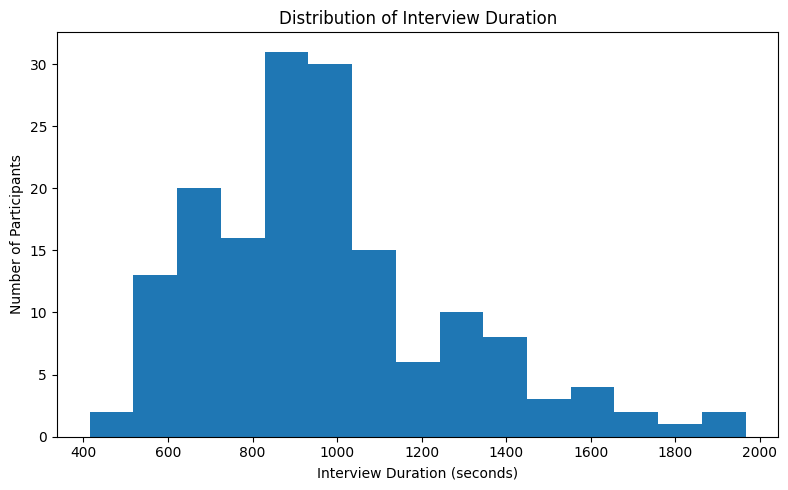

In [32]:
print(
    audio_train[
        [
            "Feature_Duration_sec",
            "eGeMAPS_Frames",
            "MFCC_Frames"
        ]
    ].describe()
)

plt.figure(figsize=(8, 5))

plt.hist(
    audio_train[
        "Feature_Duration_sec"
    ],
    bins=15
)

plt.xlabel(
    "Interview Duration (seconds)"
)

plt.ylabel(
    "Number of Participants"
)

plt.title(
    "Distribution of Interview Duration"
)

plt.tight_layout()
plt.show()

In [33]:
eg_cols = [
    c for c in audio_train.columns
    if c.startswith("eg_")
]

mfcc_cols = [
    c for c in audio_train.columns
    if c.startswith("mfcc_")
]

print(
    "eGeMAPS participant-level features:",
    len(eg_cols)
)

print(
    "MFCC participant-level features:",
    len(mfcc_cols)
)

eGeMAPS participant-level features: 69
MFCC participant-level features: 117


In [34]:
eg_stats = (
    audio_train[eg_cols]
    .describe()
    .T
)

display(
    eg_stats
)

,count,mean,std,min,25%,50%,75%,max
eg_Loudness_sma3_mean,163.0,0.097196,0.066438,0.035688,0.063176,0.081228,0.115862,0.640995
eg_Loudness_sma3_std,163.0,0.108829,0.057399,0.030718,0.070900,0.095631,0.130163,0.490607
eg_Loudness_sma3_median,163.0,0.048174,0.049789,0.018103,0.026111,0.034502,0.051724,0.485032
eg_alphaRatio_sma3_mean,163.0,-16.198696,1.646386,-23.921766,-17.246953,-15.959504,-15.231943,-11.802723
eg_alphaRatio_sma3_std,163.0,7.457848,0.872716,4.412302,6.958975,7.534959,8.006778,11.544902
...,...,...,...,...,...,...,...,...
eg_F3frequency_sma3nz_std,163.0,235.559525,21.021859,188.173908,223.216748,232.904647,248.976138,305.092141
eg_F3frequency_sma3nz_median,163.0,2532.179485,60.849814,2387.359000,2484.859750,2528.112000,2572.878750,2702.441500
eg_F3amplitudeLogRelF0_sma3nz_mean,163.0,-41.030722,4.999108,-57.860040,-43.944149,-40.915206,-37.925936,-29.938318
eg_F3amplitudeLogRelF0_sma3nz_std,163.0,36.366714,2.608216,28.026207,34.822588,36.419788,37.825872,45.093553


In [35]:
mfcc_stats = (
    audio_train[mfcc_cols]
    .describe()
    .T
)

display(
    mfcc_stats
)

,count,mean,std,min,25%,50%,75%,max
mfcc_pcm_fftMag_mfcc[0]_mean,163.0,-4.691881,3.592746,-11.188435,-6.790716,-4.972319,-3.215902,16.321471
mfcc_pcm_fftMag_mfcc[0]_std,163.0,13.408329,2.067563,6.860397,12.155126,13.544820,14.903926,20.184041
mfcc_pcm_fftMag_mfcc[0]_median,163.0,-7.528983,4.203750,-12.983350,-10.273360,-8.041557,-6.081759,14.495605
mfcc_pcm_fftMag_mfcc[1]_mean,163.0,-2.736043,2.633694,-12.728402,-4.404524,-2.626404,-0.923782,5.127016
mfcc_pcm_fftMag_mfcc[1]_std,163.0,11.996957,2.199105,6.588567,10.199037,12.085791,13.468690,17.998582
...,...,...,...,...,...,...,...,...
mfcc_pcm_fftMag_mfcc_de_de[11]_std,163.0,1.168270,0.071198,1.011783,1.118642,1.160562,1.214244,1.411779
mfcc_pcm_fftMag_mfcc_de_de[11]_median,163.0,0.000717,0.004285,-0.012789,-0.001850,0.000868,0.003289,0.016180
mfcc_pcm_fftMag_mfcc_de_de[12]_mean,163.0,-0.000011,0.000043,-0.000289,-0.000011,-0.000002,0.000005,0.000033
mfcc_pcm_fftMag_mfcc_de_de[12]_std,163.0,0.889004,0.204194,0.376733,0.722146,0.885595,1.037308,1.330286


In [36]:
eg_mean_cols = [
    c for c in eg_cols
    if c.endswith("_mean")
]

eg_class_means = (
    audio_train
    .groupby("PHQ_Binary")[
        eg_mean_cols
    ]
    .mean()
    .T
)

eg_class_means.columns = [
    "PHQ_0",
    "PHQ_1"
]

eg_class_means[
    "Absolute_Difference"
] = (
    eg_class_means["PHQ_1"]
    -
    eg_class_means["PHQ_0"]
).abs()

eg_class_means = (
    eg_class_means
    .sort_values(
        "Absolute_Difference",
        ascending=False
    )
)

display(
    eg_class_means.head(20)
)

,PHQ_0,PHQ_1,Absolute_Difference
eg_F1frequency_sma3nz_mean,613.531985,622.477008,8.945024
eg_F1bandwidth_sma3nz_mean,1386.793827,1394.483710,7.689883
eg_F2frequency_sma3nz_mean,1590.065536,1593.463236,3.397700
eg_F1amplitudeLogRelF0_sma3nz_mean,-21.761760,-23.129410,1.367650
eg_F2amplitudeLogRelF0_sma3nz_mean,-33.951344,-35.249684,1.298340
eg_F3amplitudeLogRelF0_sma3nz_mean,-40.770578,-41.916619,1.146041
eg_F3frequency_sma3nz_mean,2549.987281,2550.778271,0.790990
eg_logRelF0-H1-A3_sma3nz_mean,6.710640,5.999777,0.710863
eg_mfcc3_sma3_mean,9.010475,8.355045,0.655431
eg_F0semitoneFrom27.5Hz_sma3nz_mean,7.643108,7.042633,0.600475


Top exploratory features:
eg_F1frequency_sma3nz_mean
eg_F1bandwidth_sma3nz_mean
eg_F2frequency_sma3nz_mean
eg_F1amplitudeLogRelF0_sma3nz_mean
eg_F2amplitudeLogRelF0_sma3nz_mean
eg_F3amplitudeLogRelF0_sma3nz_mean


/tmp/ipykernel_16/2585702770.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


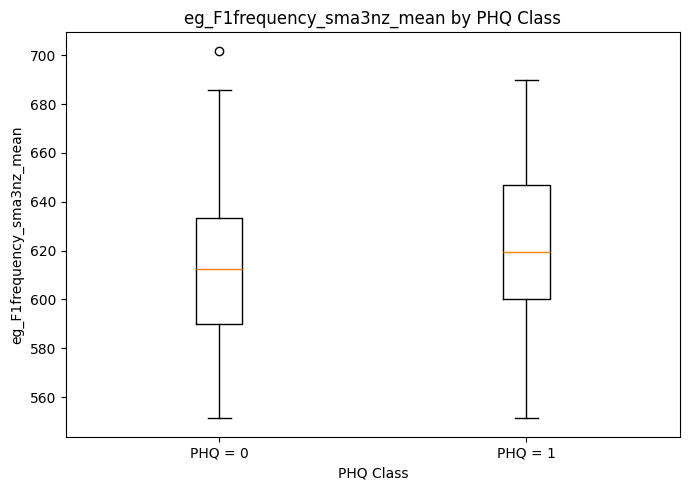

/tmp/ipykernel_16/2585702770.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


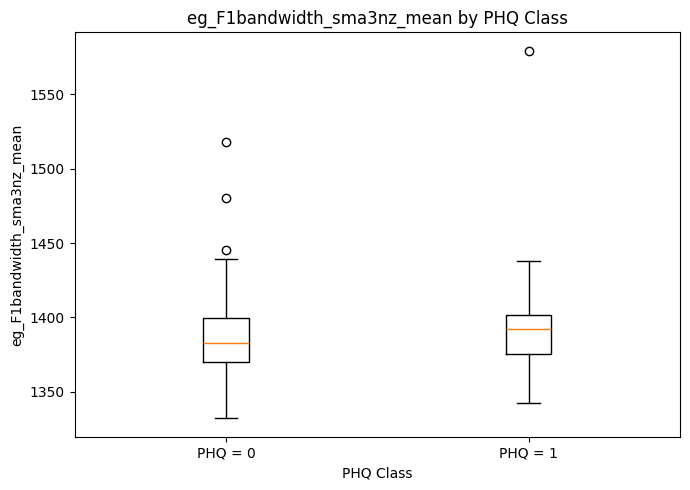

/tmp/ipykernel_16/2585702770.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


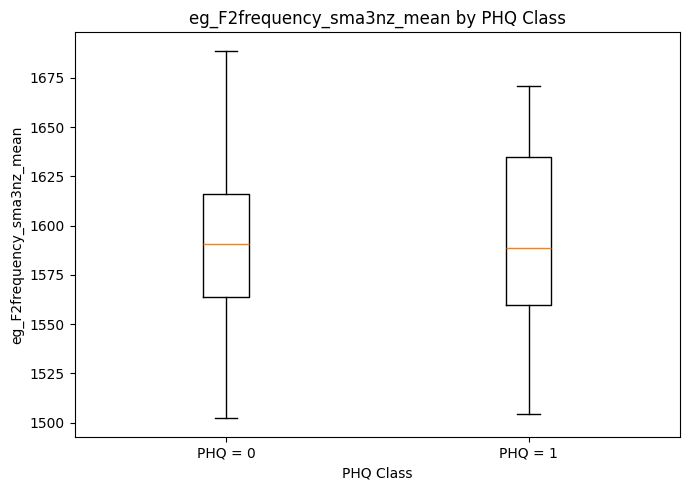

/tmp/ipykernel_16/2585702770.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


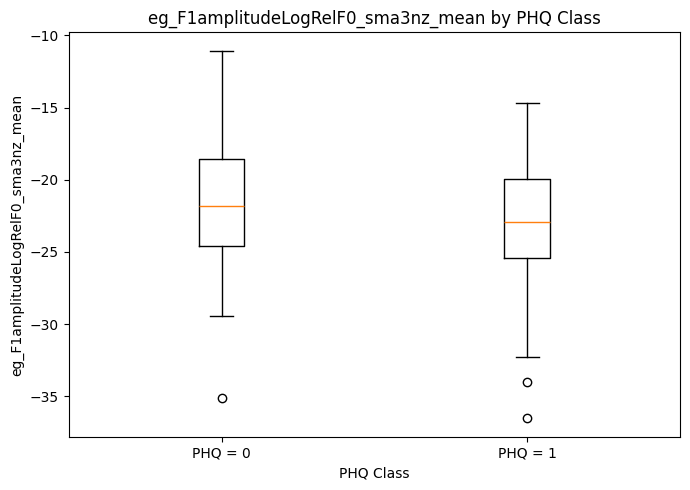

/tmp/ipykernel_16/2585702770.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


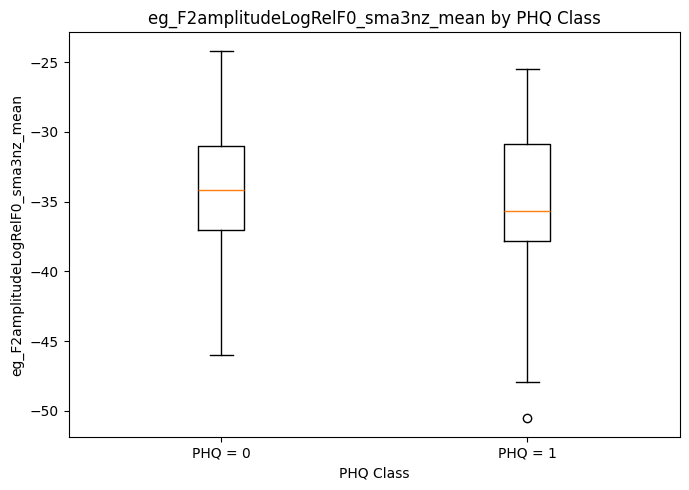

/tmp/ipykernel_16/2585702770.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


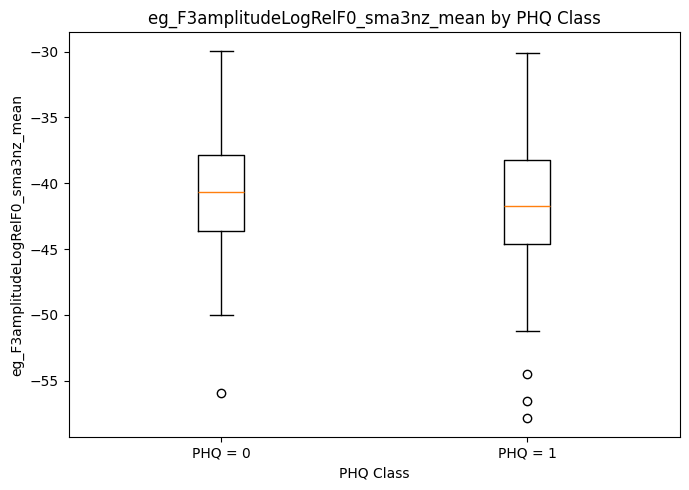

In [37]:
top_features = (
    eg_class_means
    .head(6)
    .index
    .tolist()
)

print(
    "Top exploratory features:"
)

for f in top_features:
    print(f)

for feature in top_features:

    values_0 = audio_train.loc[
        audio_train["PHQ_Binary"] == 0,
        feature
    ].dropna()

    values_1 = audio_train.loc[
        audio_train["PHQ_Binary"] == 1,
        feature
    ].dropna()

    plt.figure(figsize=(7, 5))

    plt.boxplot(
        [
            values_0,
            values_1
        ],
        labels=[
            "PHQ = 0",
            "PHQ = 1"
        ]
    )

    plt.xlabel("PHQ Class")
    plt.ylabel(feature)

    plt.title(
        f"{feature} by PHQ Class"
    )

    plt.tight_layout()
    plt.show()

In [38]:
mfcc_mean_cols = [
    c for c in mfcc_cols
    if c.endswith("_mean")
]

mfcc_class_means = (
    audio_train
    .groupby("PHQ_Binary")[
        mfcc_mean_cols
    ]
    .mean()
    .T
)

mfcc_class_means.columns = [
    "PHQ_0",
    "PHQ_1"
]

mfcc_class_means[
    "Absolute_Difference"
] = (
    mfcc_class_means["PHQ_1"]
    -
    mfcc_class_means["PHQ_0"]
).abs()

mfcc_class_means = (
    mfcc_class_means
    .sort_values(
        "Absolute_Difference",
        ascending=False
    )
)

display(
    mfcc_class_means.head(20)
)

,PHQ_0,PHQ_1,Absolute_Difference
mfcc_pcm_fftMag_mfcc[4]_mean,-3.903756,-2.128204,1.775552
mfcc_pcm_fftMag_mfcc[12]_mean,76.316675,74.743778,1.572897
mfcc_pcm_fftMag_mfcc[10]_mean,0.866748,-0.363173,1.229922
mfcc_pcm_fftMag_mfcc[6]_mean,0.287630,1.437282,1.149652
mfcc_pcm_fftMag_mfcc[2]_mean,-0.279277,-0.981226,0.701949
mfcc_pcm_fftMag_mfcc[9]_mean,-2.053782,-2.681589,0.627807
mfcc_pcm_fftMag_mfcc[0]_mean,-4.550565,-5.173120,0.622555
mfcc_pcm_fftMag_mfcc[11]_mean,-2.034152,-1.453524,0.580628
mfcc_pcm_fftMag_mfcc[8]_mean,1.961504,1.631781,0.329723
mfcc_pcm_fftMag_mfcc[5]_mean,-6.254999,-6.441531,0.186531


/tmp/ipykernel_16/1407726749.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


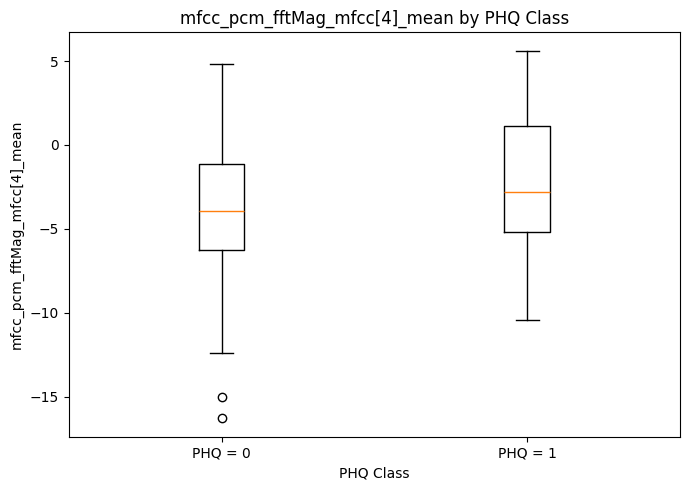

/tmp/ipykernel_16/1407726749.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


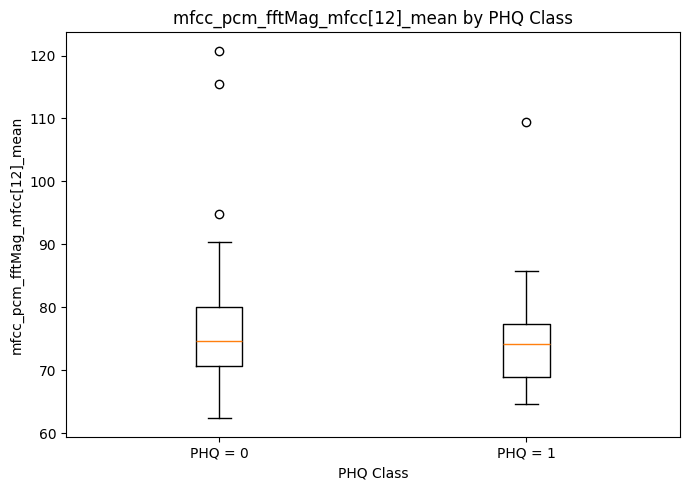

/tmp/ipykernel_16/1407726749.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


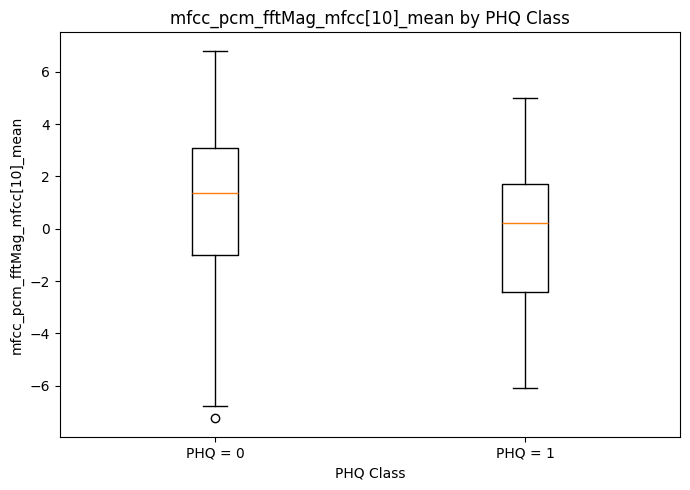

/tmp/ipykernel_16/1407726749.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


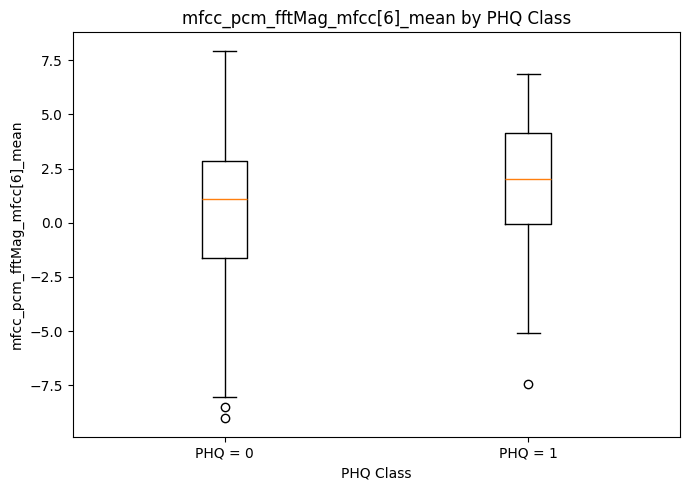

/tmp/ipykernel_16/1407726749.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


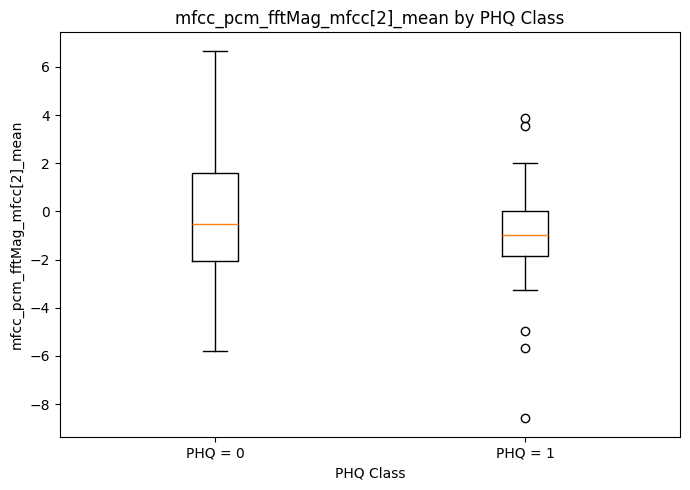

/tmp/ipykernel_16/1407726749.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


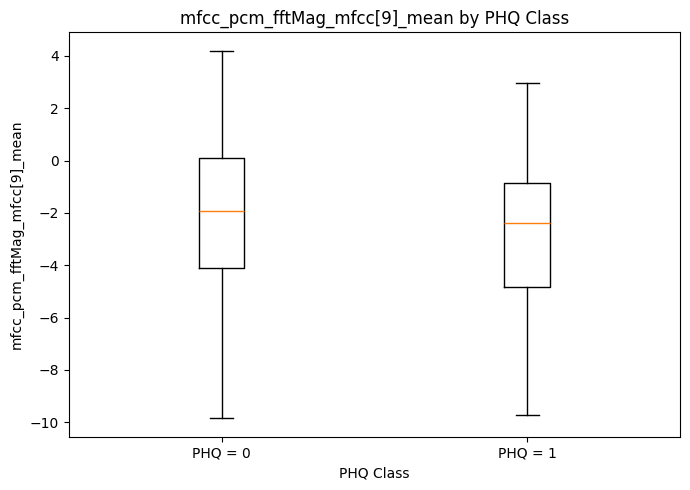

In [39]:
top_mfcc_features = (
    mfcc_class_means
    .head(6)
    .index
    .tolist()
)

for feature in top_mfcc_features:

    values_0 = audio_train.loc[
        audio_train["PHQ_Binary"] == 0,
        feature
    ].dropna()

    values_1 = audio_train.loc[
        audio_train["PHQ_Binary"] == 1,
        feature
    ].dropna()

    plt.figure(figsize=(7, 5))

    plt.boxplot(
        [
            values_0,
            values_1
        ],
        labels=[
            "PHQ = 0",
            "PHQ = 1"
        ]
    )

    plt.xlabel("PHQ Class")
    plt.ylabel(feature)

    plt.title(
        f"{feature} by PHQ Class"
    )

    plt.tight_layout()
    plt.show()

In [40]:
from scipy.stats import pointbiserialr

correlation_results = []

for feature in eg_mean_cols:

    temp = audio_train[
        [
            feature,
            "PHQ_Binary"
        ]
    ].dropna()

    if temp[feature].nunique() <= 1:
        continue

    r, p = pointbiserialr(
        temp["PHQ_Binary"],
        temp[feature]
    )

    correlation_results.append(
        {
            "Feature": feature,
            "Correlation": r,
            "P_Value": p
        }
    )

eg_corr = pd.DataFrame(
    correlation_results
)

eg_corr["Abs_Correlation"] = (
    eg_corr["Correlation"].abs()
)

eg_corr = eg_corr.sort_values(
    "Abs_Correlation",
    ascending=False
)

display(
    eg_corr.head(20)
)

,Feature,Correlation,P_Value,Abs_Correlation
12,eg_shimmerLocaldB_sma3nz_mean,-0.173260,0.026982,0.173260
18,eg_F1amplitudeLogRelF0_sma3nz_mean,-0.133335,0.089736,0.133335
15,eg_logRelF0-H1-A3_sma3nz_mean,-0.122593,0.118996,0.122593
16,eg_F1frequency_sma3nz_mean,0.118801,0.130933,0.118801
20,eg_F2amplitudeLogRelF0_sma3nz_mean,-0.116020,0.140258,0.116020
8,eg_mfcc3_sma3_mean,-0.114420,0.145847,0.114420
17,eg_F1bandwidth_sma3nz_mean,0.114125,0.146897,0.114125
4,eg_slope500-1500_sma3_mean,0.104375,0.184860,0.104375
11,eg_jitterLocal_sma3nz_mean,-0.098124,0.212716,0.098124
22,eg_F3amplitudeLogRelF0_sma3nz_mean,-0.096326,0.221259,0.096326


In [41]:
correlation_results = []

for feature in mfcc_mean_cols:

    temp = audio_train[
        [
            feature,
            "PHQ_Binary"
        ]
    ].dropna()

    if temp[feature].nunique() <= 1:
        continue

    r, p = pointbiserialr(
        temp["PHQ_Binary"],
        temp[feature]
    )

    correlation_results.append(
        {
            "Feature": feature,
            "Correlation": r,
            "P_Value": p
        }
    )

mfcc_corr = pd.DataFrame(
    correlation_results
)

mfcc_corr["Abs_Correlation"] = (
    mfcc_corr["Correlation"].abs()
)

mfcc_corr = mfcc_corr.sort_values(
    "Abs_Correlation",
    ascending=False
)

display(
    mfcc_corr.head(20)
)

,Feature,Correlation,P_Value,Abs_Correlation
4,mfcc_pcm_fftMag_mfcc[4]_mean,0.186349,0.017231,0.186349
10,mfcc_pcm_fftMag_mfcc[10]_mean,-0.179102,0.022164,0.179102
6,mfcc_pcm_fftMag_mfcc[6]_mean,0.135693,0.084153,0.135693
24,mfcc_pcm_fftMag_mfcc_de[11]_mean,-0.128625,0.101768,0.128625
11,mfcc_pcm_fftMag_mfcc[11]_mean,0.127100,0.105927,0.127100
2,mfcc_pcm_fftMag_mfcc[2]_mean,-0.112525,0.152684,0.112525
17,mfcc_pcm_fftMag_mfcc_de[4]_mean,-0.111887,0.155041,0.111887
22,mfcc_pcm_fftMag_mfcc_de[9]_mean,-0.108705,0.167195,0.108705
15,mfcc_pcm_fftMag_mfcc_de[2]_mean,0.105413,0.180506,0.105413
21,mfcc_pcm_fftMag_mfcc_de[8]_mean,-0.089899,0.253771,0.089899


In [42]:
EDA_DIR = BASE_DIR / "eda_tables"

EDA_DIR.mkdir(
    exist_ok=True
)

eg_stats.to_csv(
    EDA_DIR / "egemaps_statistics.csv"
)

mfcc_stats.to_csv(
    EDA_DIR / "mfcc_statistics.csv"
)

eg_corr.to_csv(
    EDA_DIR / "egemaps_phq_correlation.csv",
    index=False
)

mfcc_corr.to_csv(
    EDA_DIR / "mfcc_phq_correlation.csv",
    index=False
)

eg_class_means.to_csv(
    EDA_DIR / "egemaps_phq_class_means.csv"
)

mfcc_class_means.to_csv(
    EDA_DIR / "mfcc_phq_class_means.csv"
)

print(
    "EDA tables saved."
)

EDA tables saved.


In [43]:
labels.to_csv(
    BASE_DIR / "edaic_participant_labels.csv",
    index=False
)

print("Labels saved.")

Labels saved.
